# Лабораторна робота №5
**Тема:** Прогнозування часових рядів на основі кліматичних даних  
**Виконав:** Брагнюк Андрій Романович  
**Група:** 4-8, ФІТ

**Мета:** виконати аналіз температурного ряду, побудувати моделі ARIMA, Prophet і LSTM та порівняти точність їхніх прогнозів.

Дані: [Daily Weather Time Series Data — Delhi, India](https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india). Файл `kaggel_weather_2013_to_2024.csv`, цільова ознака — середня добова температура `temp`, °C.

Комірки виконуються послідовно зверху вниз. Для першого запуску потрібен інтернет: завантажуються бібліотеки й вихідний CSV.

In [1]:
# У Colab встановлюються лише відсутні бібліотеки.
import importlib.util
import subprocess
import sys

packages = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "sklearn": "scikit-learn", "statsmodels": "statsmodels",
    "prophet": "prophet", "tensorflow": "tensorflow-cpu"
}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Необхідні бібліотеки встановлено.")

Необхідні бібліотеки встановлено.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["OMP_NUM_THREADS"] = "1"

import io
import zipfile
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import statsmodels
import sklearn
import prophet
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from prophet import Prophet
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.experimental.enable_op_determinism()
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "statsmodels:", statsmodels.__version__)
print("Prophet:", prophet.__version__, "TensorFlow:", tf.__version__)

Python: 3.12.14
pandas: 2.2.3 statsmodels: 0.15.0
Prophet: 1.5.0 TensorFlow: 2.21.0


Importing plotly failed. Interactive plots will not work.


## 1. Завантаження та перегляд даних

In [3]:
CSV_NAME = "kaggel_weather_2013_to_2024.csv"
csv_path = Path(CSV_NAME)
if not csv_path.exists():
    url = ("https://www.kaggle.com/api/v1/datasets/download/"
           "yug201/daily-climate-time-series-data-delhi-india")
    with urllib.request.urlopen(url, timeout=120) as response:
        archive_bytes = response.read()
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        members = [name for name in archive.namelist()
                   if Path(name).name == CSV_NAME]
        if len(members) != 1:
            raise ValueError("У завантаженому архіві не знайдено потрібний CSV.")
        csv_path.write_bytes(archive.read(members[0]))

raw = pd.read_csv(csv_path)
print("Розмір датасету:", raw.shape)
display(raw.head())
raw.info()
display(raw.describe().round(2))

Розмір датасету: (3557, 29)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,windspeed,sealevelpressure,conditions,Year,month,dayofweek,dayofyear,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,22.3,1008.3,"Rain, Partially cloudy",2013,4,6,104,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,17.6,1005.1,Clear,2013,4,0,105,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,27.7,1001.7,Partially cloudy,2013,4,1,106,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,22.3,1002.5,Clear,2013,4,2,107,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,12.4,1003.4,Clear,2013,4,3,108,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,windspeed,sealevelpressure,Year,month,dayofweek,dayofyear,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.0,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00,3557.00
mean,1778.00,31.37,20.08,25.40,34.28,20.94,27.31,63.76,2.46,23.14,1.78,16.39,1008.63,2019.27,6.54,3.0,185.46,19.27,26.87,1919.10,1240.91,1554.38,2137.70,1299.95,1696.89,11.29,195.58
std,1026.96,7.07,7.57,7.33,9.65,9.00,9.30,18.13,10.64,42.18,4.01,7.09,7.01,3.22,3.41,2.0,104.34,3.22,14.91,525.89,580.71,539.22,839.86,692.60,754.64,3.62,55.58
min,0.00,9.10,2.00,6.50,7.90,0.30,5.70,16.10,0.00,0.00,0.00,5.40,991.70,2013.00,1.00,0.0,1.00,13.00,1.00,686.40,181.20,586.56,636.48,18.96,560.88,1.50,73.47
25%,889.00,26.40,13.00,19.10,26.30,13.00,19.10,53.00,0.00,0.00,0.00,12.30,1002.50,2017.00,4.00,1.0,97.00,17.00,14.00,1541.55,759.36,1119.82,1534.40,752.07,1113.60,8.30,164.45
50%,1778.00,33.00,22.00,27.70,35.40,22.00,28.40,65.80,0.00,0.00,0.00,15.40,1008.50,2020.00,7.00,3.0,185.00,20.00,27.00,1823.36,1078.40,1420.20,1845.51,1080.32,1422.96,11.60,180.55
75%,2667.00,36.00,26.90,31.00,42.70,28.00,35.40,76.90,0.00,0.00,0.00,18.40,1014.90,2022.00,10.00,5.0,274.00,22.00,40.00,2341.17,1752.40,2035.80,2764.20,1864.20,2314.62,14.10,233.68
max,3556.00,47.90,34.80,39.50,57.70,41.10,47.00,99.30,203.05,100.00,45.83,203.80,1024.20,2024.00,12.00,6.0,366.00,24.00,53.00,3180.72,2581.60,2710.68,4617.20,3273.74,3727.95,20.60,352.20


## 2. Попередня обробка

In [4]:
# Для одновимірного прогнозу залишаю дату та температуру.
data = raw[["DATE", "temp"]].copy()
data["DATE"] = pd.to_datetime(data["DATE"], format="%m/%d/%Y", errors="raise")
data["temp"] = pd.to_numeric(data["temp"], errors="raise")
data = data.sort_values("DATE")
print("Пропуски у вихідних колонках:")
display(data.isna().sum().to_frame("Кількість"))
print("Рядки з повторюваною датою:")
display(data.loc[data["DATE"].duplicated(keep=False)])

# Повторні значення однієї дати об'єдную середнім.
observed = data.groupby("DATE")["temp"].mean().sort_index()
observed.index.name = "DATE"
full_daily = observed.asfreq("D")
coverage = pd.DataFrame({
    "Днів у календарі": full_daily.resample("YS").size(),
    "Днів з температурою": full_daily.resample("YS").count()
})
coverage["Відсутніх днів"] = coverage.iloc[:, 0] - coverage.iloc[:, 1]
coverage.index = coverage.index.year
print("Період:", observed.index.min().date(), "—", observed.index.max().date())
print("Відсутніх календарних днів:", int(full_daily.isna().sum()))
display(coverage)

Пропуски у вихідних колонках:
Рядки з повторюваною датою:
Період: 2013-04-14 — 2024-11-30
Відсутніх календарних днів: 693


,Кількість
DATE,0
temp,0


,DATE,temp
2613,2022-05-01,33.9
2614,2022-05-01,33.9


,Днів у календарі,Днів з температурою,Відсутніх днів
DATE,,,
2013,262,156,106
2014,365,219,146
2015,365,218,147
2016,366,219,147
2017,365,220,145
2018,365,365,0
2019,365,365,0
2020,366,366,0
2021,365,365,0


У CSV є один повтор дати 01.05.2022 з однаковою температурою. Після переходу до щоденного індексу виявлено 693 відсутні дні. Із них 691 припадає на 2013–2017 роки.

Для моделювання використано період з 01.01.2018: це зменшує обсяг заповнення. Два пропуски у вересні 2022 року заповнюються останнім відомим значенням (`ffill`). Таке заповнення не використовує майбутню температуру. Для оцінювання зберігається маска фактично наявних спостережень.

In [5]:
daily = full_daily.loc["2018-01-01":].copy()
observed_mask = daily.notna()
print("Пропущені дати робочого періоду:",
      daily.index[~observed_mask].strftime("%d.%m.%Y").tolist())
y = daily.ffill().rename("temp")
assert y.notna().all()
assert y.index.is_unique and y.index.is_monotonic_increasing
print("Кількість днів робочого ряду:", len(y))
display(y.to_frame().head())

Пропущені дати робочого періоду: ['15.09.2022', '16.09.2022']
Кількість днів робочого ряду: 2526


,temp
DATE,
2018-01-01,12.5
2018-01-02,11.8
2018-01-03,11.1
2018-01-04,10.9
2018-01-05,11.7


## 3. Дослідницький аналіз

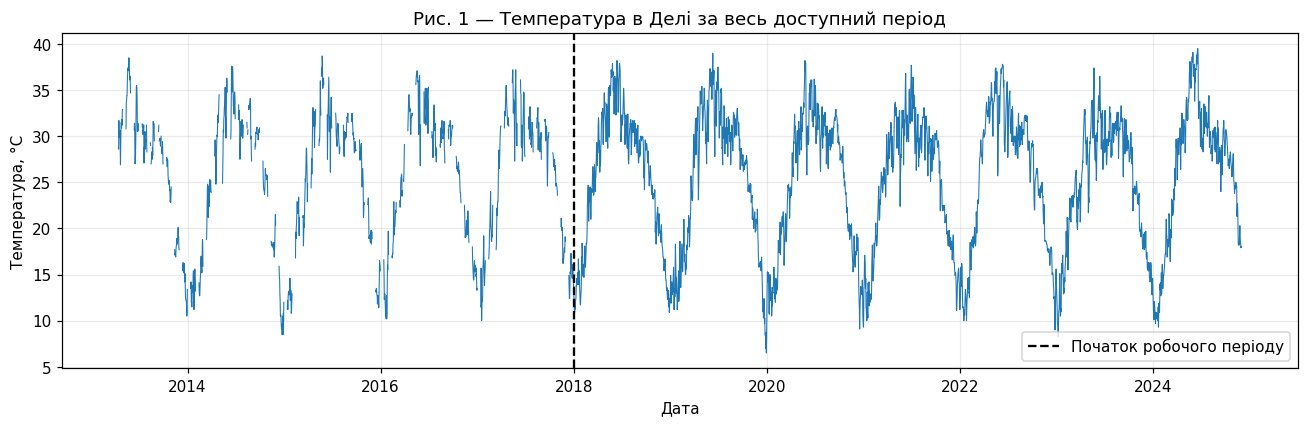

In [6]:
fig, ax = plt.subplots()
ax.plot(full_daily.index, full_daily, linewidth=0.7)
ax.axvline(pd.Timestamp("2018-01-01"), color="black", linestyle="--",
           label="Початок робочого періоду")
ax.set(title="Рис. 1 — Температура в Делі за весь доступний період",
       xlabel="Дата", ylabel="Температура, °C")
ax.legend()
plt.tight_layout()
plt.show()

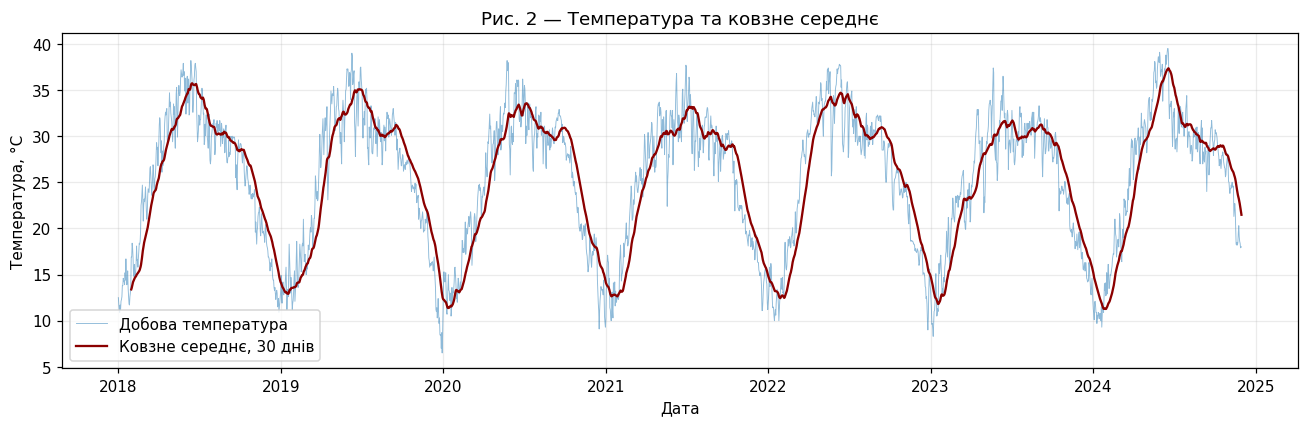

In [7]:
rolling = y.rolling(window=30, min_periods=30).mean()
fig, ax = plt.subplots()
ax.plot(y, alpha=0.5, linewidth=0.6, label="Добова температура")
ax.plot(rolling, color="darkred", linewidth=1.5, label="Ковзне середнє, 30 днів")
ax.set(title="Рис. 2 — Температура та ковзне середнє",
       xlabel="Дата", ylabel="Температура, °C")
ax.legend()
plt.tight_layout()
plt.show()

Кількість можливих викидів за правилом 1,5 IQR: 0
Межі IQR: 1.25 — 48.85 °C


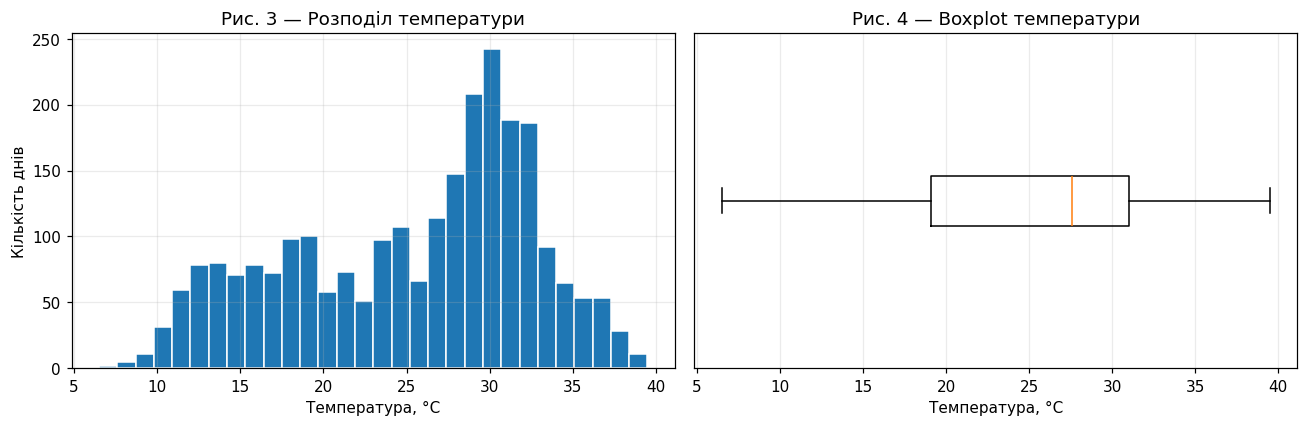

In [8]:
# Розподіл перевіряю за фактичними, а не заповненими значеннями.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(daily.dropna(), bins=30, edgecolor="white")
axes[0].set(title="Рис. 3 — Розподіл температури", xlabel="Температура, °C", ylabel="Кількість днів")
axes[1].boxplot(daily.dropna(), vert=False)
axes[1].set(title="Рис. 4 — Boxplot температури", xlabel="Температура, °C", yticks=[])
plt.tight_layout()
plt.show()
q1, q3 = daily.quantile([0.25, 0.75])
iqr = q3 - q1
outliers = daily[(daily < q1 - 1.5 * iqr) | (daily > q3 + 1.5 * iqr)]
print("Кількість можливих викидів за правилом 1,5 IQR:", len(outliers))
print("Межі IQR:", round(q1 - 1.5 * iqr, 2), "—", round(q3 + 1.5 * iqr, 2), "°C")

## 4. Розділення ряду та автокореляція

In [9]:
split = int(len(y) * 0.8)
train, test = y.iloc[:split].copy(), y.iloc[split:].copy()
test_observed = observed_mask.loc[test.index]
print("Train:", len(train), "днів;", train.index.min().date(), "—", train.index.max().date())
print("Test:", len(test), "днів;", test.index.min().date(), "—", test.index.max().date())
print("Фактичних значень у test:", int(test_observed.sum()))
assert train.index.max() < test.index.min()

Train: 2020 днів; 2018-01-01 — 2023-07-13
Test: 506 днів; 2023-07-14 — 2024-11-30
Фактичних значень у test: 506


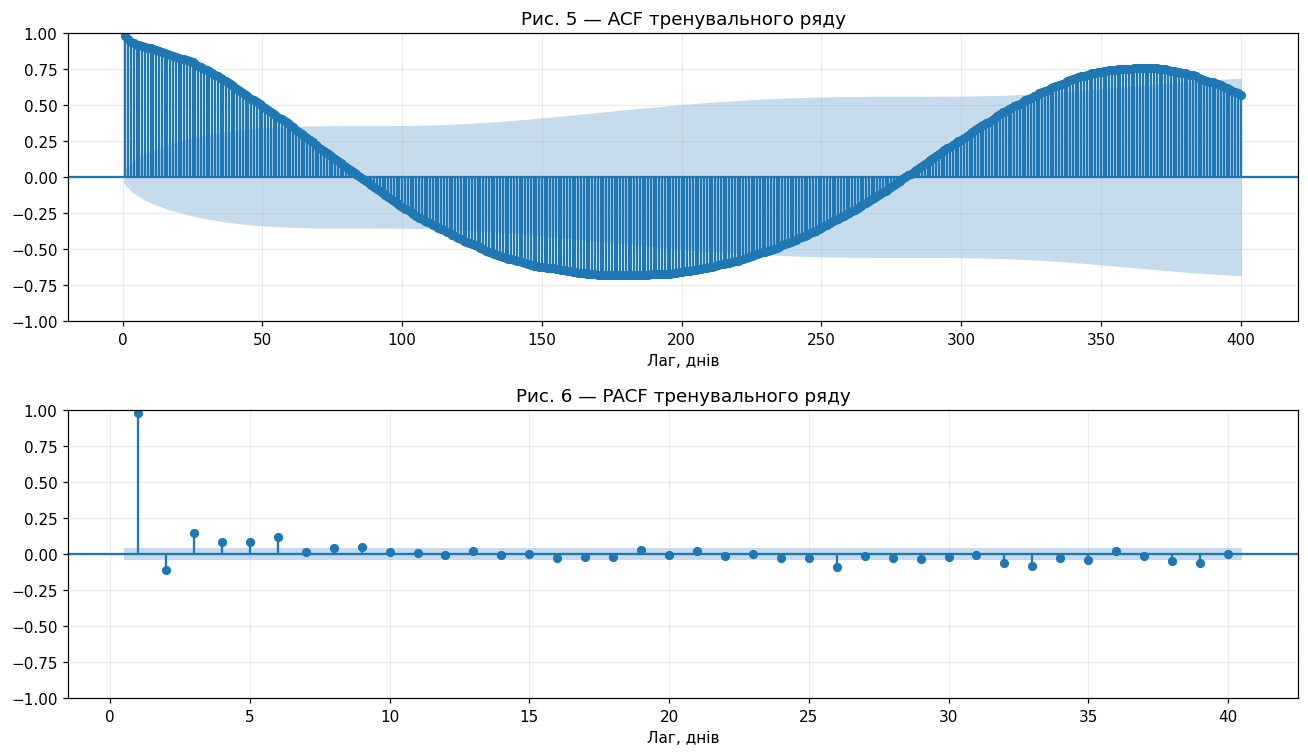

,Лаг,ACF
0,1,0.982
1,7,0.911
2,30,0.746
3,180,-0.677
4,365,0.759


,Лаг,PACF
0,1,0.982
1,2,-0.108
2,3,0.148
3,4,0.082
4,5,0.082


In [10]:
# ACF/PACF для вибору моделі розглядаю лише на train.
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
plot_acf(train, lags=400, ax=axes[0], zero=False)
axes[0].set(title="Рис. 5 — ACF тренувального ряду", xlabel="Лаг, днів")
plot_pacf(train, lags=40, method="ywm", ax=axes[1], zero=False)
axes[1].set(title="Рис. 6 — PACF тренувального ряду", xlabel="Лаг, днів")
plt.tight_layout()
plt.show()
a = acf(train, nlags=365, fft=True)
p = pacf(train, nlags=10, method="ywm")
display(pd.DataFrame({"Лаг": [1, 7, 30, 180, 365],
                      "ACF": a[[1, 7, 30, 180, 365]]}).round(3))
display(pd.DataFrame({"Лаг": np.arange(1, 6), "PACF": p[1:6]}).round(3))

Сусідні добові значення пов’язані між собою. Повторення сезонних коливань перевіряється за ACF на лагу близько 365 днів; PACF показує зв’язок після врахування проміжних лагів. Високі температурні значення автоматично не видаляються: вони можуть відповідати сезонним максимумам.

**Схема оцінювання:** усі моделі прогнозують увесь тестовий період з однієї точки — кінця `train`. Фактичні температури з `test` не подаються моделям. LSTM формує багатокроковий прогноз рекурсивно. Тестові метрики не використовуються для підбору параметрів.

In [11]:
def mape(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    nonzero = np.abs(actual) > 1e-8
    if not nonzero.any():
        return np.nan
    return np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100


def evaluate(prediction):
    assert prediction.index.equals(test.index)
    assert np.isfinite(prediction.to_numpy()).all()
    actual = test.loc[test_observed]
    predicted = prediction.loc[test_observed]
    return {"MAE, °C": mean_absolute_error(actual, predicted),
            "RMSE, °C": np.sqrt(mean_squared_error(actual, predicted)),
            "MAPE, %": mape(actual, predicted)}


def plot_prediction(prediction, title):
    fig, ax = plt.subplots()
    ax.plot(test, color="black", linewidth=0.9, label="Фактичні значення")
    ax.plot(prediction, color="darkorange", linewidth=1.1, label=prediction.name)
    ax.set(title=title, xlabel="Дата", ylabel="Температура, °C")
    ax.legend()
    plt.tight_layout()
    plt.show()

metrics = {}

MAPE обчислюється на ненульових фактичних значеннях. Для температури у °C ця метрика залежить від умовного нуля шкали, тому основний критерій порівняння — RMSE, а MAPE наведено відповідно до завдання.

## 5. Модель ARIMA

ARIMA(p, 0, q) використовується як базова несезонна модель. Значення p і q обираються за AIC на train. Річна сезонність явно враховується у Prophet; базова ARIMA та рекурсивна LSTM можуть втрачати її на довгому горизонті.

In [12]:
# Порівнюю невелику сітку моделей з однаковим порядком різницювання d=0.
orders = [(1, 0, 0), (2, 0, 0), (5, 0, 0), (7, 0, 0),
          (1, 0, 1), (2, 0, 1), (5, 0, 1), (7, 0, 1)]
aic_rows, fitted_models = [], {}
for order in orders:
    fitted = ARIMA(train, order=order, trend="c").fit()
    converged = fitted.mle_retvals.get("converged", True)
    aic_rows.append({"Порядок": str(order), "AIC": fitted.aic, "Збіжність": converged})
    if converged and np.isfinite(fitted.aic):
        fitted_models[order] = fitted
if not fitted_models:
    raise RuntimeError("Жодна ARIMA-модель не збіглася.")
display(pd.DataFrame(aic_rows).sort_values("AIC").round(3))
best_order = min(fitted_models, key=lambda order: fitted_models[order].aic)
arima_model = fitted_models[best_order]
pred_arima = pd.Series(np.asarray(arima_model.forecast(steps=len(test))),
                       index=test.index, name="ARIMA")
print("Обраний порядок ARIMA:", best_order)
print(arima_model.summary())

Обраний порядок ARIMA: (5, 0, 1)
                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 2020
Model:                 ARIMA(5, 0, 1)   Log Likelihood               -3436.880
Date:                Fri, 30 Oct 2026   AIC                           6889.761
Time:                        12:31:40   BIC                           6934.648
Sample:                    01-01-2018   HQIC                          6906.234
                         - 07-13-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         24.7481      2.734      9.050      0.000      19.389      30.108
ar.L1          1.7895      0.069     25.763      0.000       1.653       1.926
ar.L2         -1.03

/tmp/lab5env/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/tmp/lab5env/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,Порядок,AIC,Збіжність
6,"(5, 0, 1)",6889.761,True
3,"(7, 0, 0)",6892.533,True
7,"(7, 0, 1)",6895.189,True
2,"(5, 0, 0)",6921.845,True
5,"(2, 0, 1)",6977.167,True
4,"(1, 0, 1)",6986.085,True
1,"(2, 0, 0)",6995.614,True
0,"(1, 0, 0)",7018.511,True


За тестом Люнга—Бокса на перевірених лагах залишкова автокореляція зберігається.


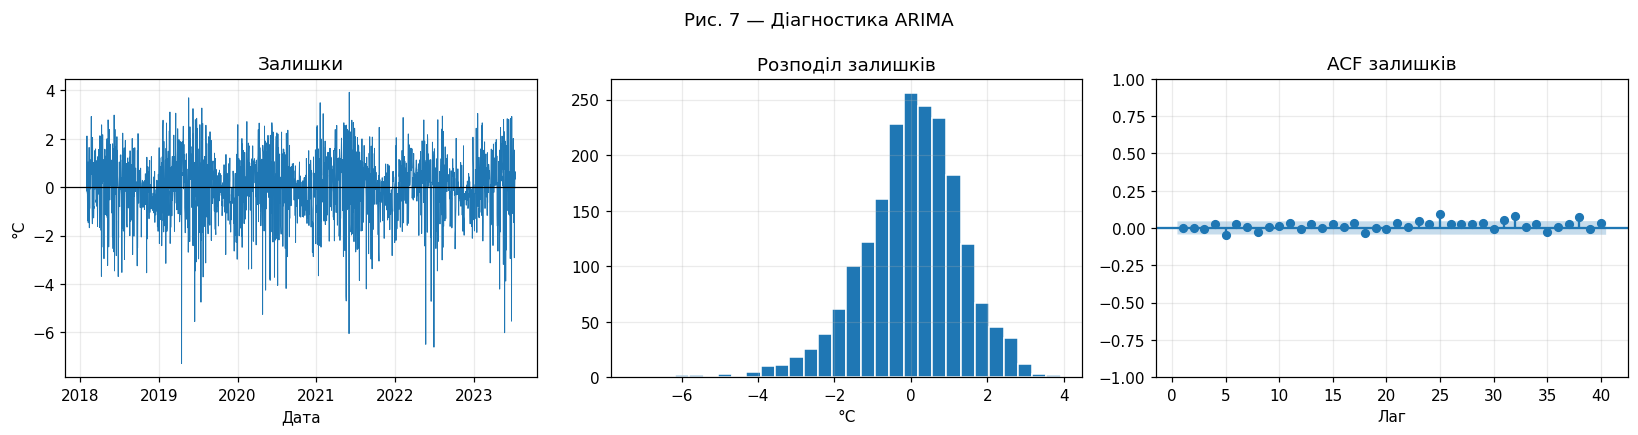

,lb_stat,lb_pvalue
14,13.4225,0.0981
30,53.7951,0.0005


,"MAE, °C","RMSE, °C","MAPE, %"
ARIMA,5.865,7.179,29.181


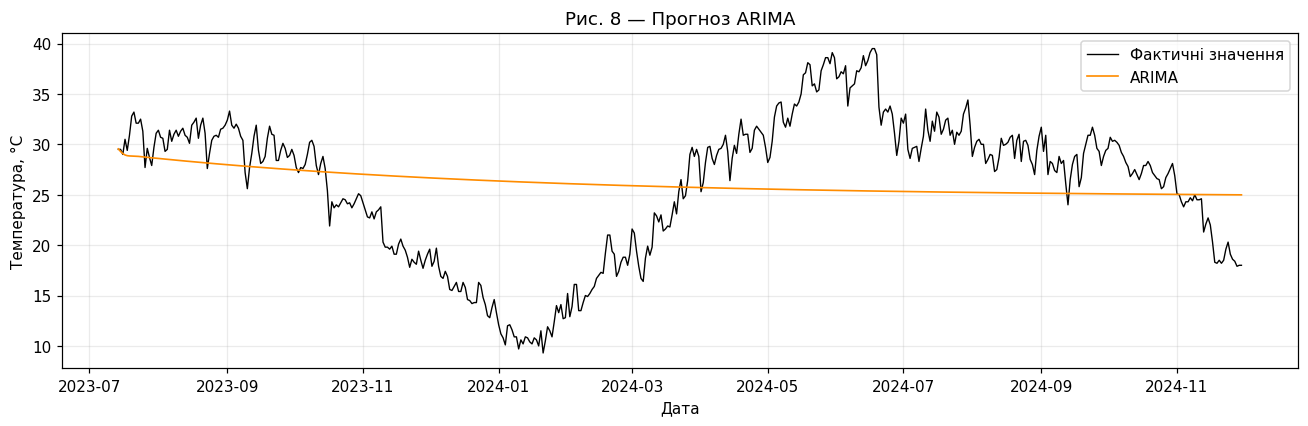

In [13]:
# Початкові залишки не включаю в діагностику через ініціалізацію моделі.
residuals = arima_model.resid.iloc[30:]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(residuals, linewidth=0.6)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(title="Залишки", xlabel="Дата", ylabel="°C")
axes[1].hist(residuals, bins=30, edgecolor="white")
axes[1].set(title="Розподіл залишків", xlabel="°C")
plot_acf(residuals, lags=40, zero=False, ax=axes[2])
axes[2].set(title="ACF залишків", xlabel="Лаг")
fig.suptitle("Рис. 7 — Діагностика ARIMA")
plt.tight_layout()
plt.show()
ljung = acorr_ljungbox(residuals, lags=[14, 30],
                       model_df=best_order[0] + best_order[2], return_df=True)
display(ljung.round(4))
if (ljung["lb_pvalue"] < 0.05).any():
    print("За тестом Люнга—Бокса на перевірених лагах залишкова автокореляція зберігається.")
else:
    print("На перевірених лагах тест Люнга—Бокса не виявив значущої автокореляції залишків.")
metrics["ARIMA"] = evaluate(pred_arima)
display(pd.DataFrame([metrics["ARIMA"]], index=["ARIMA"]).round(3))
plot_prediction(pred_arima, "Рис. 8 — Прогноз ARIMA")

## 6. Модель Prophet

12:31:41 - cmdstanpy - INFO - Chain [1] start processing
12:31:41 - cmdstanpy - INFO - Chain [1] done processing


,ds,y
0,2018-01-01,12.5
1,2018-01-02,11.8
2,2018-01-03,11.1
3,2018-01-04,10.9
4,2018-01-05,11.7


,"MAE, °C","RMSE, °C","MAPE, %"
Prophet,3.453,4.076,13.262


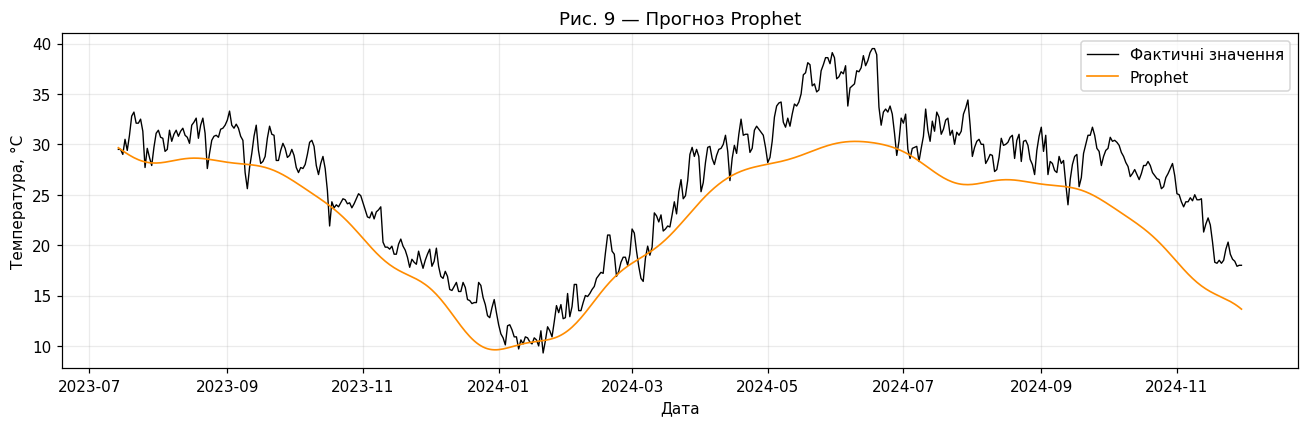

In [14]:
prophet_train = train.rename_axis("ds").reset_index(name="y")
display(prophet_train.head())
prophet_model = Prophet(yearly_seasonality=True, weekly_seasonality=False,
                        daily_seasonality=False, seasonality_mode="additive",
                        changepoint_prior_scale=0.05, uncertainty_samples=0)
prophet_model.fit(prophet_train)
future = pd.DataFrame({"ds": test.index})
prophet_forecast = prophet_model.predict(future)
pred_prophet = pd.Series(prophet_forecast["yhat"].to_numpy(),
                         index=test.index, name="Prophet")
metrics["Prophet"] = evaluate(pred_prophet)
display(pd.DataFrame([metrics["Prophet"]], index=["Prophet"]).round(3))
plot_prediction(pred_prophet, "Рис. 9 — Прогноз Prophet")

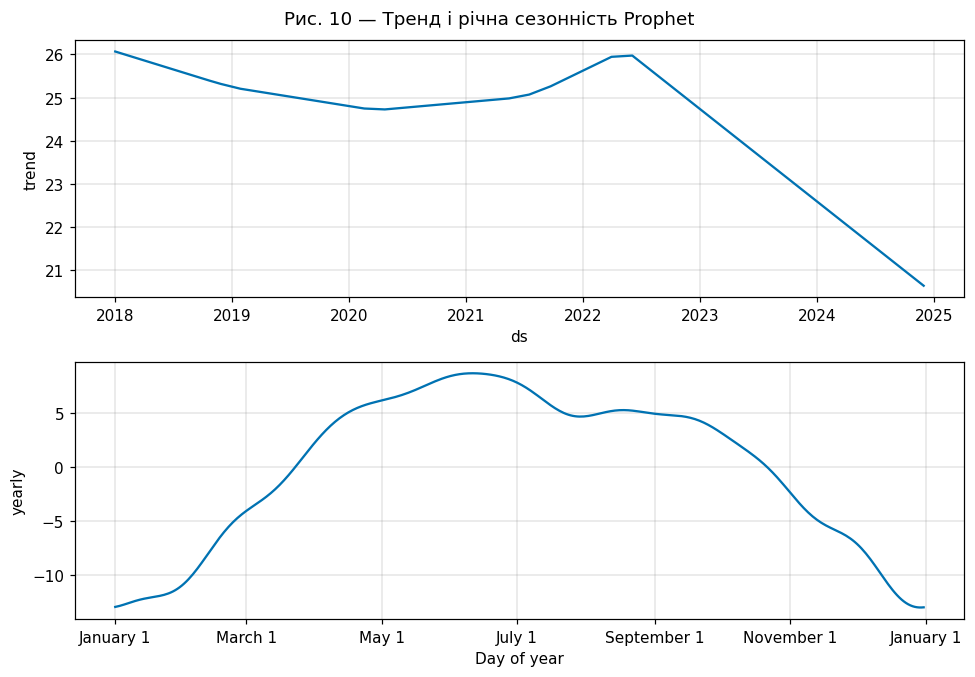

In [15]:
components = prophet_model.predict(pd.DataFrame({"ds": y.index}))
fig = prophet_model.plot_components(components)
fig.suptitle("Рис. 10 — Тренд і річна сезонність Prophet", y=1.02)
plt.show()

## 7. Модель LSTM

Вхід моделі — температура за попередні 60 днів. Останні 15% тренувального періоду використовуються для валідації та вибору кількості епох. Масштабування під час валідації навчається лише на попередній частині `train`. Після вибору кількості епох модель навчається заново на всьому `train`.

In [16]:
LOOKBACK = 60
validation_start = int(len(train) * 0.85)
scaler_validation = MinMaxScaler()
scaler_validation.fit(train.iloc[:validation_start].to_numpy().reshape(-1, 1))
scaled_validation = scaler_validation.transform(train.to_numpy().reshape(-1, 1))


def make_sequences(values, lookback):
    X = np.array([values[i-lookback:i] for i in range(lookback, len(values))], dtype=np.float32)
    target = values[lookback:].astype(np.float32)
    return X, target


X_all, y_all = make_sequences(scaled_validation, LOOKBACK)
target_positions = np.arange(LOOKBACK, len(train))
fit_mask = target_positions < validation_start
X_fit, y_fit = X_all[fit_mask], y_all[fit_mask]
X_val, y_val = X_all[~fit_mask], y_all[~fit_mask]
print("Навчальні послідовності:", X_fit.shape)
print("Валідаційні послідовності:", X_val.shape)
print("Тестовий горизонт:", len(test), "днів")

Навчальні послідовності: (1657, 60, 1)
Валідаційні послідовності: (303, 60, 1)
Тестовий горизонт: 506 днів


Виконано епох: 60
Обрана кількість епох: 60


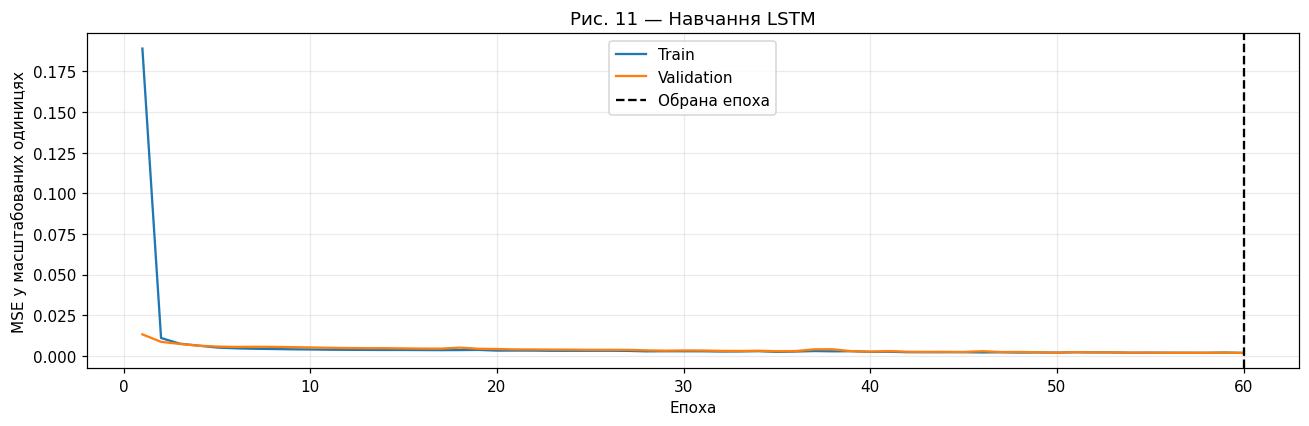

In [17]:
def build_lstm():
    model = Sequential([Input(shape=(LOOKBACK, 1)),
                        LSTM(32), Dense(16, activation="relu"), Dense(1)])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="mse")
    return model


def make_dataset(X, target):
    dataset = tf.data.Dataset.from_tensor_slices((X, target)).batch(32)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    return dataset.with_options(options)


tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
validation_model = build_lstm()
early_stop = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
history = validation_model.fit(make_dataset(X_fit, y_fit),
    validation_data=make_dataset(X_val, y_val), epochs=60,
    callbacks=[early_stop], shuffle=False, verbose=0)
best_epochs = int(np.argmin(history.history["val_loss"]) + 1)
print("Виконано епох:", len(history.history["loss"]))
print("Обрана кількість епох:", best_epochs)
fig, ax = plt.subplots()
ax.plot(np.arange(1, len(history.history["loss"])+1), history.history["loss"], label="Train")
ax.plot(np.arange(1, len(history.history["val_loss"])+1), history.history["val_loss"], label="Validation")
ax.axvline(best_epochs, color="black", linestyle="--", label="Обрана епоха")
ax.set(title="Рис. 11 — Навчання LSTM", xlabel="Епоха", ylabel="MSE у масштабованих одиницях")
ax.legend()
plt.tight_layout()
plt.show()

In [18]:
# Фінальне навчання: scaler бачить train, але не test.
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train.to_numpy().reshape(-1, 1))
X_train, y_train = make_sequences(train_scaled, LOOKBACK)
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
lstm_model = build_lstm()
lstm_model.fit(make_dataset(X_train, y_train), epochs=best_epochs, shuffle=False, verbose=0)
lstm_model.summary()

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 14,693 (57.40 KB)
 Trainable params: 4,897 (19.13 KB)
 Non-trainable params: 0 (0.00 B)
 Optimizer params: 9,796 (38.27 KB)


,"MAE, °C","RMSE, °C","MAPE, %"
LSTM,8.409,10.803,46.285


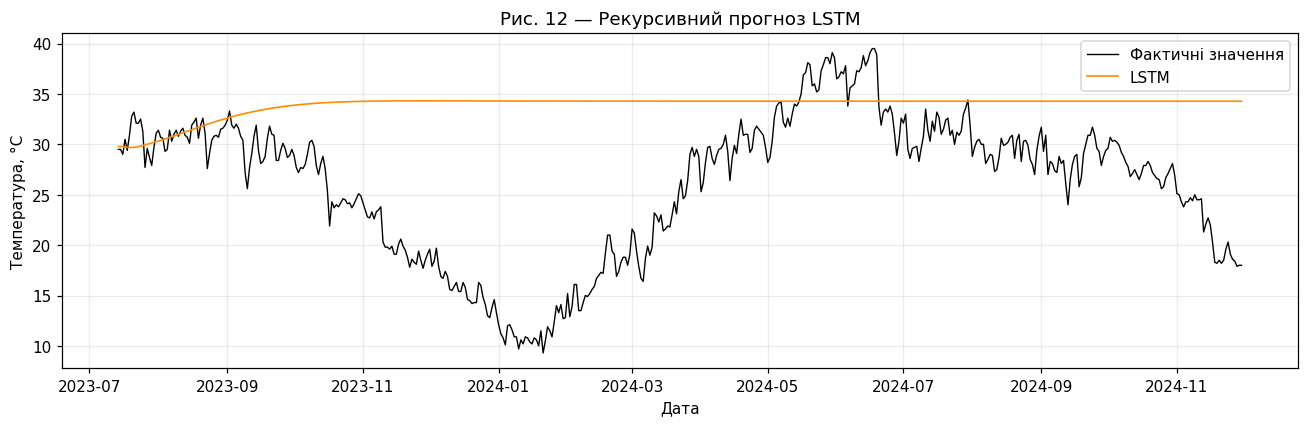

In [19]:
# Кожне нове передбачення повертається у вхідне вікно.
window = train_scaled[-LOOKBACK:].astype(np.float32).copy()
scaled_predictions = []
for _ in range(len(test)):
    next_value = float(lstm_model(window[np.newaxis, ...], training=False).numpy()[0, 0])
    scaled_predictions.append(next_value)
    window = np.concatenate([window[1:], np.array([[next_value]], dtype=np.float32)])
lstm_values = scaler.inverse_transform(np.array(scaled_predictions).reshape(-1, 1)).ravel()
pred_lstm = pd.Series(lstm_values, index=test.index, name="LSTM")
metrics["LSTM"] = evaluate(pred_lstm)
display(pd.DataFrame([metrics["LSTM"]], index=["LSTM"]).round(3))
plot_prediction(pred_lstm, "Рис. 12 — Рекурсивний прогноз LSTM")

## 8. Порівняння моделей

Таблиця 1 — Точність прогнозів на однаковому тестовому періоді
Найменша RMSE у моделі Prophet: 4.076 °C.
MAE: 3.453 °C; MAPE: 13.262%.


,"MAE, °C","RMSE, °C","MAPE, %"
Модель,,,
Prophet,3.453,4.076,13.262
ARIMA,5.865,7.179,29.181
LSTM,8.409,10.803,46.285


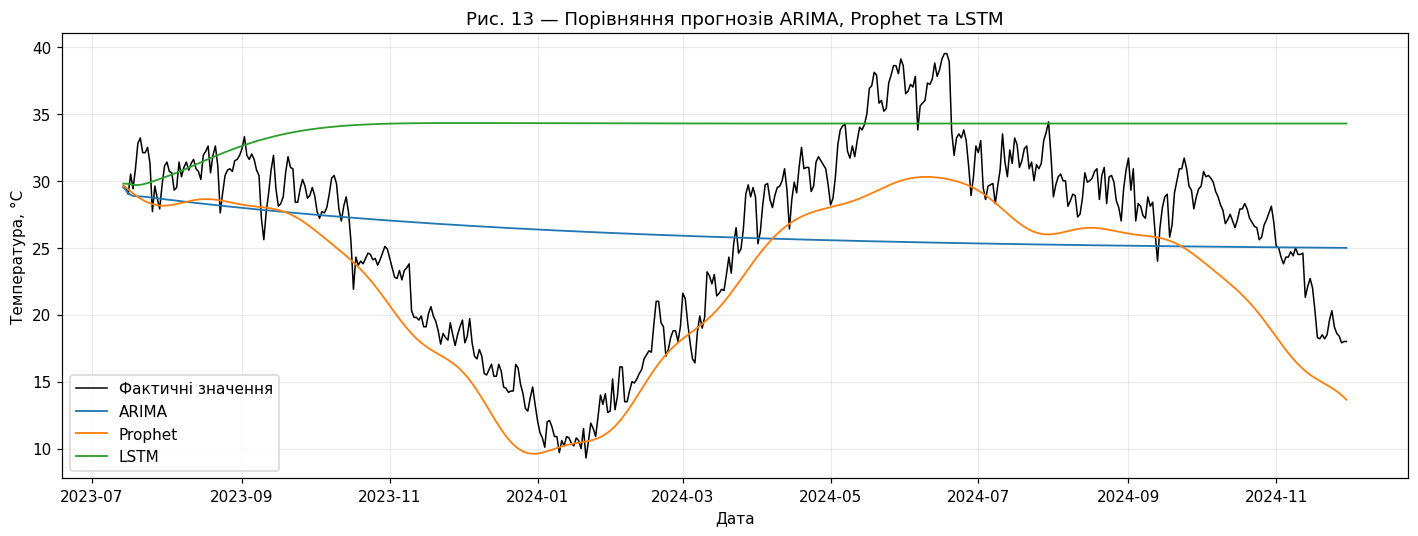

In [20]:
results = pd.DataFrame.from_dict(metrics, orient="index").sort_values("RMSE, °C")
results.index.name = "Модель"
print("Таблиця 1 — Точність прогнозів на однаковому тестовому періоді")
display(results.round(3))
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test, color="black", linewidth=1, label="Фактичні значення")
for prediction in [pred_arima, pred_prophet, pred_lstm]:
    ax.plot(prediction, linewidth=1.2, label=prediction.name)
ax.set(title="Рис. 13 — Порівняння прогнозів ARIMA, Prophet та LSTM",
       xlabel="Дата", ylabel="Температура, °C")
ax.legend()
plt.tight_layout()
plt.show()
best = results.index[0]
print(f"Найменша RMSE у моделі {best}: {results.loc[best, 'RMSE, °C']:.3f} °C.")
print(f"MAE: {results.loc[best, 'MAE, °C']:.3f} °C; MAPE: {results.loc[best, 'MAPE, %']:.3f}%.")

## 9. Короткий підсумок

Після перевірки дат і пропусків для прогнозування використано щоденний ряд за 2018–2024 роки. ACF на лагу 365 днів становить 0,759, що узгоджується з річною сезонністю. На тестових 506 днях найменшу RMSE отримано для Prophet: 4,076 °C; MAE — 3,453 °C, MAPE — 13,262%. Результат стосується обраного розбиття та налаштувань. Несезонна ARIMA й рекурсивна LSTM гірше відтворили коливання на цьому горизонті.